# Redes Neuronales V · Karen Sofía Delgado Calderon

Práctica académica de verificación y reconocimiento cerrado con fotografías de Labeled Faces in the Wild. Se separan identidades para ajuste, calibración y prueba. La primera ejecución descarga el conjunto público mediante scikit-learn. Los resultados muestran recuentos agregados.

- [Fuente y preparación de LFW](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_lfw_people.html)
- [FaceNet](https://doi.org/10.1109/CVPR.2015.7298682)

In [1]:
"""Práctica de comparación facial en el conjunto cerrado LFW."""
from pathlib import Path
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import fetch_lfw_people
from sklearn.metrics import roc_auc_score, roc_curve
from torch import nn
from torch.nn import functional as F

SEMILLA = 487
EPOCAS, LOTES, TRIOS = 24, 8, 48
MARGEN = 0.30
torch.set_num_threads(2)
torch.manual_seed(SEMILLA)
rng = np.random.default_rng(SEMILLA)

## Datos y partición

In [2]:
def preparar(datos):
    """Conserva luminancia y comprueba copias exactas del recorte."""
    grupos, vistas = {}, set()
    for clase in np.unique(datos.target):
        indices = rng.permutation(np.flatnonzero(datos.target == clase))
        seleccion = []
        for idx in indices:
            huella = hashlib.sha256(datos.images[idx].tobytes()).digest()
            if huella not in vistas:
                vistas.add(huella)
                seleccion.append(idx)
            if len(seleccion) == 24:
                break
        if len(seleccion) >= 20:
            grupos[int(clase)] = np.array(seleccion)
    imagenes = torch.as_tensor(datos.images, dtype=torch.float32).unsqueeze(1)
    imagenes = F.interpolate(imagenes, (40, 30), mode="area")
    media = imagenes.mean(dim=(2, 3), keepdim=True)
    desvio = imagenes.std(dim=(2, 3), keepdim=True).clamp_min(1e-6)
    return (imagenes - media) / desvio, grupos


def partir(grupos):
    clases = rng.permutation(list(grupos))
    ajuste, calibracion, prueba = clases[22:], clases[:10], clases[10:22]
    if len(ajuste) < 2:
        raise ValueError("LFW no contiene suficientes identidades elegibles.")
    return dict(ajuste=ajuste, calibracion=calibracion, prueba=prueba)

## Codificador y ajuste

In [3]:
class Codificador(nn.Module):
    def __init__(self):
        super().__init__()
        self.capas = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 48, 3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 3)), nn.Flatten(), nn.Linear(576, 32),
        )

    def forward(self, imagenes):
        return F.normalize(self.capas(imagenes), dim=1)


def ajustar(modelo, imagenes, grupos, clases):
    optimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)
    criterio = nn.TripletMarginLoss(margin=MARGEN)
    historial = []
    for epoca in range(EPOCAS):
        costos = []
        for _ in range(LOTES):
            anclas, positivos, negativos = [], [], []
            for _ in range(TRIOS):
                clase, otra = rng.choice(clases, 2, replace=False)
                a, p = rng.choice(grupos[clase], 2, replace=False)
                anclas.append(a)
                positivos.append(p)
                negativos.append(rng.choice(grupos[otra]))
            optimizador.zero_grad()
            z = modelo(imagenes[anclas + positivos + negativos])
            costo = criterio(*z.chunk(3))
            costo.backward()
            optimizador.step()
            costos.append(costo.item())
        historial.append(float(np.mean(costos)))
        if epoca == 0 or (epoca + 1) % 6 == 0:
            print(f"Época {epoca + 1:2d}/{EPOCAS} | pérdida {historial[-1]:.5f}", flush=True)
    return historial

## Evaluación fuera del ajuste

In [4]:
def episodios(clases, grupos, semilla, cantidad):
    generador = np.random.default_rng(semilla)
    for _ in range(cantidad):
        bloques = np.stack([generador.permutation(grupos[c])[:15] for c in clases])
        yield bloques[:, :5], bloques[:, 5:].reshape(-1)


def distancias(vectores, soporte, consultas, k):
    prototipos = F.normalize(vectores[soporte[:, :k]].mean(dim=1), dim=1)
    return torch.cdist(vectores[consultas], prototipos).numpy()


def evaluar(vectores, grupos, particion, k):
    cal = list(episodios(particion["calibracion"], grupos, 900, 10))
    test = list(episodios(particion["prueba"], grupos, 1000, 20))
    d_cal = np.concatenate([distancias(vectores, *e, k) for e in cal])
    verdad_cal = np.tile(np.repeat(np.arange(len(particion["calibracion"])), 10), len(cal))
    coincide_cal = verdad_cal[:, None] == np.arange(d_cal.shape[1])
    far_cal, tar_cal, umbrales = roc_curve(coincide_cal.ravel(), -d_cal.ravel())
    umbral = float(-umbrales[np.argmax(tar_cal - far_cal)])

    d = np.concatenate([distancias(vectores, *e, k) for e in test])
    verdad = np.tile(np.repeat(np.arange(len(particion["prueba"])), 10), len(test))
    coincide = verdad[:, None] == np.arange(d.shape[1])
    aceptado = d <= umbral
    aciertos = int((d.argmin(axis=1) == verdad).sum())
    fa = int(aceptado[~coincide].sum())
    fr = int((~aceptado[coincide]).sum())
    return {
        "referencias": k, "umbral": umbral, "aciertos": aciertos,
        "consultas": len(verdad), "exactitud": aciertos / len(verdad),
        "fa": fa, "fr": fr, "negativas": int((~coincide).sum()),
        "positivas": int(coincide.sum()), "far": float(aceptado[~coincide].mean()),
        "frr": float((~aceptado[coincide]).mean()),
        "auc": float(roc_auc_score(coincide.ravel(), -d.ravel())),
    }

## Ejecución y evidencia

In [5]:
def ejecutar(salida, cache=None):
    datos = fetch_lfw_people(
        data_home=cache, funneled=True, color=False, min_faces_per_person=20, resize=0.5
    )
    imagenes, grupos = preparar(datos)
    particion = partir(grupos)
    inventario = {
        fase: {"identidades": len(ids), "imagenes": sum(len(grupos[i]) for i in ids)}
        for fase, ids in particion.items()
    }
    print("LFW | identidad separada por fase", flush=True)
    for fase, fila in inventario.items():
        print(f"{fase:12} {fila['identidades']:3} identidades / {fila['imagenes']:4} imágenes")
    modelo = Codificador()
    historial = ajustar(modelo, imagenes, grupos, particion["ajuste"])
    modelo.eval()
    with torch.inference_mode():
        embeddings = torch.cat([modelo(bloque) for bloque in imagenes.split(128)])
        pixeles = F.normalize(imagenes.flatten(1), dim=1)
    filas = []
    for nombre, vectores in [("Píxeles", pixeles), ("Siamesa", embeddings)]:
        for k in (1, 5):
            fila = dict(modelo=nombre, **evaluar(vectores, grupos, particion, k))
            filas.append(fila)
            print(f"{nombre:8} k={k} | {fila['aciertos']:4}/{fila['consultas']} "
                  f"| exactitud {fila['exactitud']:.2%} | AUC {fila['auc']:.3f} "
                  f"| FAR {fila['far']:.2%} | FRR {fila['frr']:.2%}")

    salida.mkdir(parents=True, exist_ok=True)
    resumen = {
        "semilla": SEMILLA, "forma_origen": list(datos.images.shape),
        "particiones": inventario, "parametros": sum(p.numel() for p in modelo.parameters()),
        "episodios_calibracion": 10, "episodios_prueba": 20,
        "historial": historial, "resultados": filas,
    }
    (salida / "resumen_lfw.json").write_text(
        json.dumps(resumen, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf8"
    )
    fig, ejes = plt.subplots(1, 2, figsize=(9, 3.25), layout="constrained")
    ejes[0].plot(range(1, EPOCAS + 1), historial, color="#125e76", marker=".", lw=1.6)
    ejes[0].set(xlabel="Época", ylabel="Pérdida media", title="Ajuste con Triplet Loss")
    for i, (nombre, color) in enumerate([("Píxeles", "#778899"), ("Siamesa", "#125e76")]):
        ys = [r["exactitud"] * 100 for r in filas if r["modelo"] == nombre]
        barras = ejes[1].bar(np.arange(2) + i * 0.32, ys, 0.30, color=color, label=nombre)
        ejes[1].bar_label(barras, fmt="%.1f", fontsize=8)
    ejes[1].set(xticks=[0.16, 1.16], xticklabels=["1 referencia", "5 referencias"],
                ylim=(0, 100), ylabel="Exactitud (%)", title="Identidades reservadas")
    ejes[1].legend(loc="upper left", frameon=False, fontsize=8)
    fig.savefig(salida / "resultados_lfw.png", dpi=180)
    plt.close(fig)
    print("Práctica LFW finalizada.", flush=True)

LFW | identidad separada por fase


ajuste        40 identidades /  929 imágenes
calibracion   10 identidades /  234 imágenes
prueba        12 identidades /  280 imágenes


Época  1/24 | pérdida 0.25030


Época  6/24 | pérdida 0.19686


Época 12/24 | pérdida 0.14939


Época 18/24 | pérdida 0.09713


Época 24/24 | pérdida 0.10013


Píxeles  k=1 |  501/2400 | exactitud 20.88% | AUC 0.604 | FAR 45.71% | FRR 40.75%
Píxeles  k=5 |  805/2400 | exactitud 33.54% | AUC 0.679 | FAR 46.57% | FRR 29.50%
Siamesa  k=1 |  699/2400 | exactitud 29.12% | AUC 0.753 | FAR 31.43% | FRR 31.37%
Siamesa  k=5 | 1039/2400 | exactitud 43.29% | AUC 0.841 | FAR 24.32% | FRR 23.92%


Práctica LFW finalizada.


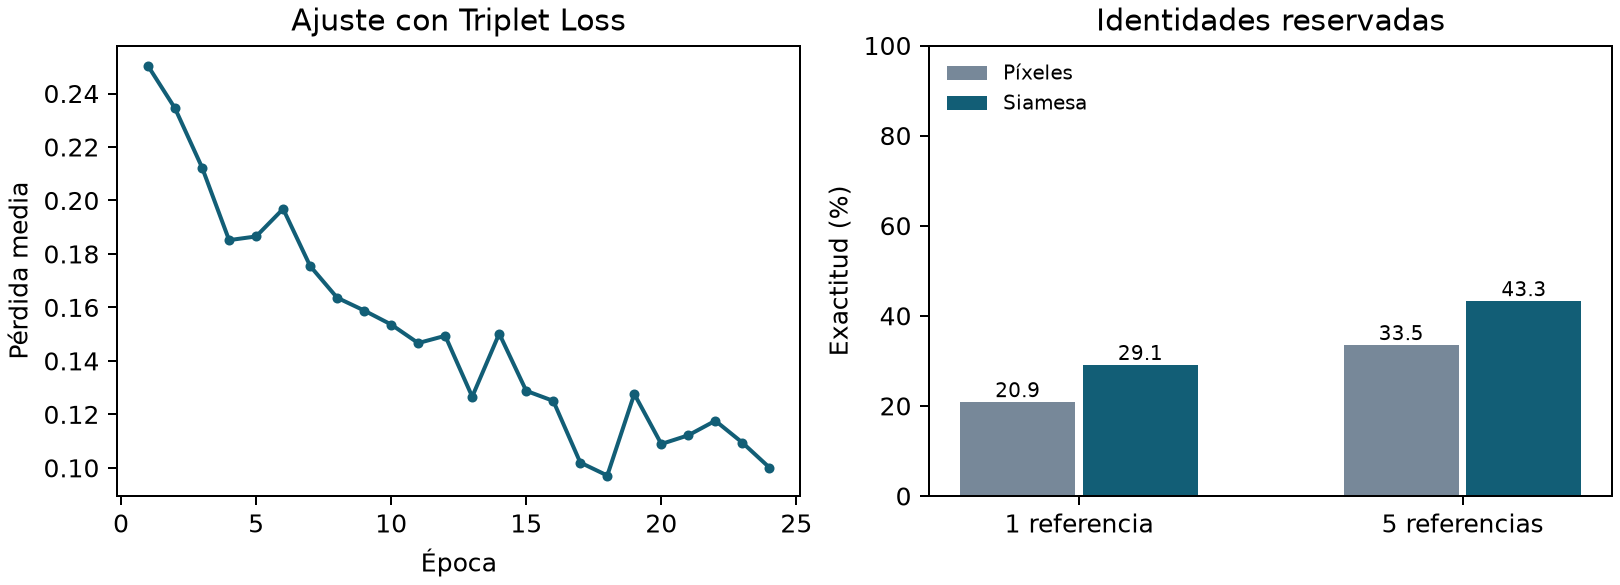

In [6]:
import os
from IPython.display import Image, display

salida = Path("resultados_lfw")
ejecutar(salida, os.environ.get("LFW_CACHE"))
display(Image(filename=str(salida / "resultados_lfw.png")))

## Lectura de los resultados

La exactitud mide la clase del prototipo más cercano. FAR y FRR describen la aceptación por umbral; AUC resume la separación de pares sin fijar un umbral. Las fotos de soporte y consulta son distintas dentro de cada episodio y pueden reutilizarse entre episodios. Zero-shot se discute como concepto, ya que ambas condiciones usan fotos de referencia.